# Turnover and conversion

Roadmap step 2, part 3. Did the parties separate because members were replaced, or because sitting members changed?

For each pair of consecutive Congresses and each party, the change in the party's mean splits exactly into three parts:

- **Conversion:** members in that party in both Congresses changed. People are matched by Bioguide ID; only 2 of 43,726 member records lack one.
- **Switching:** members who moved between the Democratic and Republican parties, measured from the party's earlier mean.
- **Replacement:** new members compared with departing members, also measured from the earlier mean.

Measuring arrivals and departures from the earlier mean keeps the parts exact and stops them depending on where the scale's zero is. Unit tests check both.

The parts are summed over two windows, from the Congress beginning in 1901 to the one beginning in 1969, and from 1969 to 2023. Other start years are tested below. Plots also show the unfinished 119th Congress, but the window tables don't include it.

Two measures are decomposed:

1. **The Nokken-Poole party gap**, Republican mean minus Democratic mean. DW-NOMINATE can't be used, because its scores are fixed within a party spell, so its conversion part is always zero. The check below confirms this.
2. **The defection rate**, the share of party-opposed roll calls on which a member voted with the other party's majority, averaged over the two parties. It comes from votes alone. Members need at least 20 party-opposed votes.

Only Democrats and Republicans are included. A switch to or from an independent or third party, such as Jeffords in 2001, therefore counts as a departure or arrival under replacement.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from clustering import decompose_change, defection_rates
from voteview import load_members, load_rollcalls, load_votes

COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

INCOMPLETE_CONGRESS = 119
MIN_PARTY_MEMBERS = 10
CHAMBERS = ["House", "Senate"]
PARTS = ["conversion", "switching", "replacement"]
PART_STYLES = {"conversion": (COLORS["D"], "-"), "switching": (NEUTRAL, ":"), "replacement": (COLORS["R"], "-"), "total": ("#0b0b0b", "--")}
WINDOWS = {"1901 to 1969": (57, 91), "1969 to 2023": (91, 118)}


def first_year(congress):
    return 1789 + 2 * (congress - 1)


members = load_members()
members = members[~members["is_delegate"] & members["party"].isin(["D", "R"])].copy()
members["person"] = members["bioguide_id"].fillna("icpsr:" + members["icpsr"].astype(str))
counts = members.groupby(["congress", "chamber"])["party"].value_counts().unstack(fill_value=0)
selected = counts[(counts["D"] >= MIN_PARTY_MEMBERS) & (counts["R"] >= MIN_PARTY_MEMBERS)].index
print(len(selected), "Congress and chamber combinations")


170 Congress and chamber combinations


## Decomposing the Nokken-Poole party gap

Member records without a Bioguide ID, linked by ICPSR instead: 2 of 43726


Largest DW-NOMINATE conversion term (should be 0, because scores are fixed within a party spell): 0.0
Largest error in parts adding up to the total: 3.0531133177191805e-16


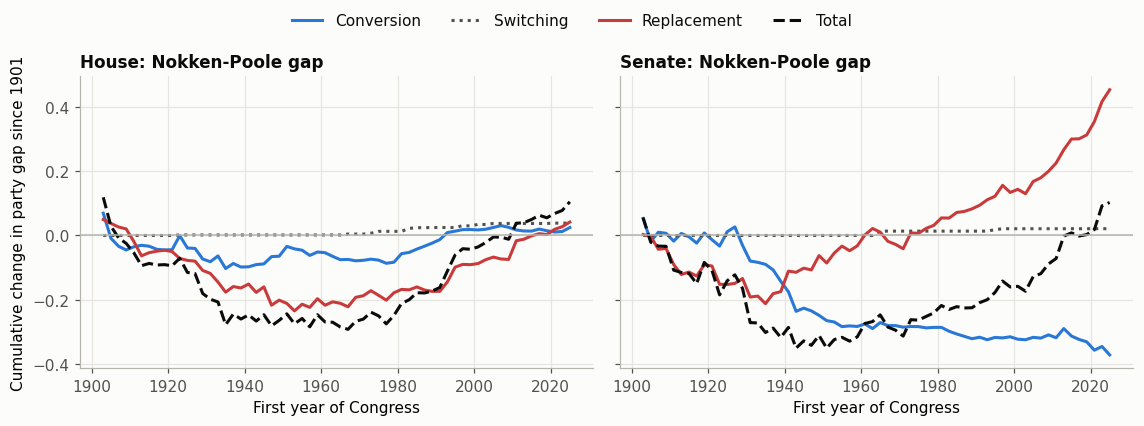

Nokken-Poole gap: change in each window and its parts


conversion  switching  replacement  total  \
chamber window                                                    
House   1901 to 1969      -0.079      0.004       -0.192 -0.267   
        1969 to 2023       0.091      0.034        0.219  0.344   
Senate  1901 to 1969      -0.280      0.013       -0.028 -0.294   
        1969 to 2023      -0.065      0.007        0.444  0.386   

                      conversion_share  
chamber window                          
House   1901 to 1969             0.295  
        1969 to 2023             0.264  
Senate  1901 to 1969             0.952  
        1969 to 2023            -0.168

Party by party, 1969 to 2023 (positive means further right)


chamber,House,Senate
D_conversion,-0.071,0.021
D_switching,-0.025,-0.010
D_replacement,0.008,-0.101
D_total,-0.088,-0.090
R_conversion,0.020,-0.043
R_switching,0.009,-0.003
R_replacement,0.227,0.343
R_total,0.256,0.297


Nokken-Poole gap with different start years


conversion  switching  replacement  total  \
chamber window                                                    
House   1965 to 2023       0.087      0.037        0.238  0.362   
        1969 to 2023       0.091      0.034        0.219  0.344   
        1973 to 2023       0.086      0.031        0.199  0.316   
        1979 to 2023       0.095      0.026        0.205  0.326   
Senate  1965 to 2023      -0.074      0.007        0.406  0.339   
        1969 to 2023      -0.065      0.007        0.444  0.386   
        1973 to 2023      -0.062      0.007        0.408  0.354   
        1979 to 2023      -0.059      0.007        0.385  0.333   

                      conversion_share  
chamber window                          
House   1965 to 2023             0.241  
        1969 to 2023             0.264  
        1973 to 2023             0.271  
        1979 to 2023             0.292  
Senate  1965 to 2023            -0.219  
        1969 to 2023            -0.168  
        1973 to 2023            -0.175  
        1979 to 2023            -0.178

Party switchers between Democrats and Republicans found, 1969 to 2023:


,chamber,year,direction,name
0,House,1973,to_D,"REID, Ogden Rogers"
1,House,1975,to_R,"JARMAN, John"
2,House,1975,to_D,"RIEGLE, Donald Wayne, Jr."
3,House,1981,to_R,"ATKINSON, Eugene Vincent"
4,House,1983,to_R,"GRAMM, William Philip (Phil)"
5,House,1983,to_R,"STUMP, Robert Lee"
6,House,1985,to_R,"IRELAND, Andrew Poysell (Andy)"
7,House,1989,to_R,"GRANT, James William"
8,House,1989,to_R,"ROBINSON, Tommy Franklin"
9,House,1995,to_R,"DEAL, John Nathan"


In [2]:
def party_scores(frame, column):
    """One value per person and party in a Congress; a mid-Congress switcher appears once in each party."""
    return frame.dropna(subset=[column]).groupby(["congress", "chamber", "party", "person"])[column].mean()


def decompose_series(scores):
    rows, skipped = [], []
    available = set(scores.index.droplevel("person"))
    for chamber in CHAMBERS:
        congresses = sorted(c for c, room in selected if room == chamber)
        for before, after in zip(congresses, congresses[1:]):
            if after != before + 1:
                continue
            needed = [(c, chamber, p) for c in (before, after) for p in ("D", "R")]
            if not all(key in available for key in needed):
                skipped.append((chamber, after))
                continue
            parts = {}
            for party, other in [("D", "R"), ("R", "D")]:
                parts[party] = decompose_change(
                    scores.loc[(before, chamber, party)], scores.loc[(after, chamber, party)],
                    scores.loc[(before, chamber, other)].index, scores.loc[(after, chamber, other)].index,
                )
            row = {"chamber": chamber, "congress": after, "year": first_year(after)}
            for part in PARTS + ["total"]:
                row[part] = parts["R"][part] - parts["D"][part]
                row[f"D_{part}"], row[f"R_{part}"] = parts["D"][part], parts["R"][part]
            # A switcher leaves one party and joins the other, so each appears once on each side.
            row["to_R"] = parts["R"]["switched_in"]
            row["to_D"] = parts["D"]["switched_in"]
            rows.append(row)
    if skipped:
        print(f"Skipped {len(skipped)} transitions with no eligible members in a party:", skipped)
    return pd.DataFrame(rows)


def window_table(changes, scale=1, windows=WINDOWS):
    rows = []
    for chamber, frame in changes.groupby("chamber"):
        for name, (start, end) in windows.items():
            part = frame[(frame["congress"] > start) & (frame["congress"] <= end)]
            row = {"chamber": chamber, "window": name}
            for column in PARTS + ["total"]:
                row[column] = part[column].sum() * scale
            row["conversion_share"] = row["conversion"] / row["total"] if row["total"] else np.nan
            rows.append(row)
    return pd.DataFrame(rows).set_index(["chamber", "window"])


def plot_cumulative(changes, title, ylabel, scale=1):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
    for axis, chamber in zip(axes, CHAMBERS):
        frame = changes[(changes["chamber"] == chamber) & (changes["congress"] > 57)].sort_values("year")
        for part in PARTS + ["total"]:
            color, style = PART_STYLES[part]
            axis.plot(frame["year"], frame[part].cumsum() * scale, color=color, linestyle=style, label=part.capitalize())
        axis.axhline(0, color="#b5b4ad", linewidth=1)
        axis.set_title(f"{chamber}: {title}")
        axis.set_xlabel("First year of Congress")
    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()


START_WINDOWS = {f"{first_year(start)} to 2023": (start, 118) for start in [89, 91, 93, 96]}
print("Member records without a Bioguide ID, linked by ICPSR instead:", members["bioguide_id"].isna().sum(), "of", len(members))
np_changes = decompose_series(party_scores(members, "nokken_poole_dim1"))
dw_changes = decompose_series(party_scores(members, "nominate_dim1"))
print("Largest DW-NOMINATE conversion term (should be 0, because scores are fixed within a party spell):",
      dw_changes["conversion"].abs().max())
print("Largest error in parts adding up to the total:",
      (np_changes[PARTS].sum(axis=1) - np_changes["total"]).abs().max())
plot_cumulative(np_changes, "Nokken-Poole gap", "Cumulative change in party gap since 1901")
print("Nokken-Poole gap: change in each window and its parts")
display(window_table(np_changes).round(3))
print("Party by party, 1969 to 2023 (positive means further right)")
display(np_changes[np_changes["congress"].between(92, 118)].groupby("chamber")[
    [f"{p}_{part}" for p in ["D", "R"] for part in PARTS + ["total"]]].sum().T.round(3))
print("Nokken-Poole gap with different start years")
display(window_table(np_changes, windows=START_WINDOWS).round(3))

names = members.drop_duplicates("person").set_index("person")["bioname"]
switches = np_changes[np_changes["congress"].between(92, 118)].melt(
    id_vars=["chamber", "year"], value_vars=["to_R", "to_D"], var_name="direction", value_name="people").explode("people").dropna()
switches["name"] = switches["people"].map(names)
print("Party switchers between Democrats and Republicans found, 1969 to 2023:")
display(switches[["chamber", "year", "direction", "name"]].sort_values(["chamber", "year"]).reset_index(drop=True))


**What this shows**

**1969 to 2023 (separation)**

- **House:** the gap grew by 0.344. Replacement contributed 0.219 (64%), conversion 0.091 (26%) and switching 0.034 (10%).
- **Senate:** the gap grew by 0.386. Replacement contributed 0.444, more than the whole change, because sitting senators slightly offset it (-0.065).
- **The change is mostly on the Republican side.** Republican means moved right by 0.256 in the House and 0.297 in the Senate, almost all through replacement. Democratic means moved left by 0.088 and 0.090.
- House Democrats moved left mainly through conversion (-0.071), so sitting House Democrats changed. Senate Democrats moved left mainly through replacement.
- **Robust to the start year:** for starts from 1965 to 1979, replacement is always the largest part. In the House it ranges from 0.199 to 0.238, and conversion stays at 24% to 29% of the change. In the Senate, replacement exceeds the total change for every start year.
- **Switchers:** 19 House and 3 Senate members switched between the parties from 1969 to 2023. Most switched from Democrat to Republican, especially in 1995.

**1901 to 1969 (narrowing)**

- **House:** the gap shrank by 0.267, mostly from replacement (-0.192).
- **Senate:** the gap shrank by 0.294, almost all from conversion (-0.280).

**Limits**

- Nokken-Poole uses fixed DW-NOMINATE cutting lines, which may limit how far a sitting member can appear to move, so conversion may be understated.
- Noise in a new member's first score is counted under replacement, and later changes under conversion.
- No sampling uncertainty is estimated. Treat the direction as more reliable than the exact shares.

## Decomposing defection from party, a measure without NOMINATE

Average defection rate on party-opposed votes, selected Congresses (members with 20+ such votes)


chamber,House,Senate
year,,
1901,0.084,0.097
1947,0.138,0.181
1969,0.285,0.271
1987,0.167,0.191
2007,0.070,0.116
2023,0.050,0.054


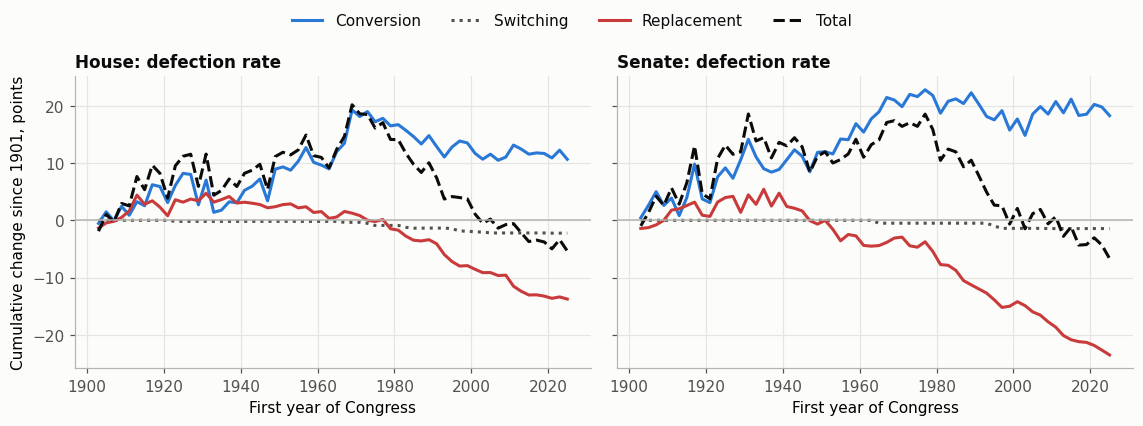

Defection rate in percentage points: change in each window and its parts


conversion  switching  replacement  total  \
chamber window                                                    
House   1901 to 1969       19.26      -0.35         1.24  20.16   
        1969 to 2023       -7.03      -1.90       -14.61 -23.53   
Senate  1901 to 1969       20.98      -0.50        -3.10  17.38   
        1969 to 2023       -1.21      -0.94       -19.55 -21.70   

                      conversion_share  
chamber window                          
House   1901 to 1969              0.96  
        1969 to 2023              0.30  
Senate  1901 to 1969              1.21  
        1969 to 2023              0.06

Same, counting only members with 50+ party-opposed votes


Skipped 2 transitions with no eligible members in a party: [('House', 70), ('House', 71)]


conversion  switching  replacement  total  \
chamber window                                                    
House   1901 to 1969       21.85      -0.36         4.33  25.82   
        1969 to 2023       -7.03      -1.87       -14.84 -23.74   
Senate  1901 to 1969       25.68      -0.50        -6.12  19.06   
        1969 to 2023       -1.08      -0.94       -20.13 -22.14   

                      conversion_share  
chamber window                          
House   1901 to 1969              0.85  
        1969 to 2023              0.30  
Senate  1901 to 1969              1.35  
        1969 to 2023              0.05

Defection rate with different start years


conversion  switching  replacement  total  \
chamber window                                                    
House   1965 to 2023        0.24      -2.06       -13.95 -15.77   
        1969 to 2023       -7.03      -1.90       -14.61 -23.53   
        1973 to 2023       -6.74      -1.71       -13.39 -21.84   
        1979 to 2023       -4.24      -1.35       -11.89 -17.48   
Senate  1965 to 2023        0.83      -0.94       -18.24 -18.35   
        1969 to 2023       -1.21      -0.94       -19.55 -21.70   
        1973 to 2023       -2.21      -0.94       -18.21 -21.35   
        1979 to 2023       -2.02      -0.94       -17.22 -20.17   

                      conversion_share  
chamber window                          
House   1965 to 2023             -0.02  
        1969 to 2023              0.30  
        1973 to 2023              0.31  
        1979 to 2023              0.24  
Senate  1965 to 2023             -0.05  
        1969 to 2023              0.06  
        1973 to 2023              0.10  
        1979 to 2023              0.10

In [3]:
votes = load_votes().merge(load_rollcalls().loc[lambda r: ~r["is_lopsided"], ["congress", "chamber", "rollnumber"]])
votes = votes.merge(members[["congress", "chamber", "icpsr", "party", "person"]], on=["congress", "chamber", "icpsr"])
rates = defection_rates(votes).merge(members[["congress", "chamber", "icpsr", "person"]].drop_duplicates(), on=["congress", "chamber", "icpsr"])
del votes


def defection_changes(min_votes):
    eligible = rates[rates["count"] >= min_votes]
    scores = eligible.groupby(["congress", "chamber", "party", "person"])["mean"].mean()
    changes = decompose_series(scores)
    for column in PARTS + ["total"]:
        # Average of the two parties' changes; the decomposition above returned R minus D.
        changes[column] = (changes[f"D_{column}"] + changes[f"R_{column}"]) / 2
    return changes


defections = defection_changes(20)
level = rates[rates["count"] >= 20].groupby(["congress", "chamber", "party"])["mean"].mean().unstack().mean(axis=1).rename("defection").reset_index()
level["year"] = first_year(level["congress"])
print("Average defection rate on party-opposed votes, selected Congresses (members with 20+ such votes)")
display(level[level["congress"].isin([57, 80, 91, 100, 110, 118])].pivot(index="year", columns="chamber", values="defection").round(3))
plot_cumulative(defections, "defection rate", "Cumulative change since 1901, points", scale=100)
print("Defection rate in percentage points: change in each window and its parts")
display(window_table(defections, scale=100).round(2))
print("Same, counting only members with 50+ party-opposed votes")
display(window_table(defection_changes(50), scale=100).round(2))
print("Defection rate with different start years")
display(window_table(defections, scale=100, windows=START_WINDOWS).round(2))


**What this shows**

The average defection rate on party-opposed votes rose from about 8% to 10% around 1901 to 28.5% (House) and 27.1% (Senate) in 1969. It then fell to about 5% in 2023.

- **1969 to 2023:** defection fell by 23.5 points in the House. Replacement accounts for 14.6 points (62%), conversion 7.0 (30%) and switching 1.9. In the Senate it fell by 21.7 points, with 19.6 from replacement (90%).
- **Replacement is robust to the start year; conversion isn't.** For starts from 1965 to 1979, House replacement is 11.9 to 14.6 points and always the largest part. House conversion ranges from +0.2 to -7.0 points, because 1965 to 1969 was itself a period of rising defection. In the Senate, replacement is 84% or more of the change for every start year.
- **Requiring at least 50 party-opposed votes** gives nearly the same results from 1969 on. Before 1969 the window changes more (House total 20.2 becomes 25.8 points), partly because two House transitions in the 1920s then have too few eligible members and are skipped.
- **1901 to 1969:** defection rose by about 20 points in the House and 17 in the Senate, almost entirely within sitting members (19.3 and 21.0 points of conversion).

**Limits**

- Conversion on this measure includes changes in which votes reach the floor. The same members facing a different mix of votes would show up as conversion, so the large conversion before 1969 may partly reflect new kinds of votes rather than members changing.
- Members who cross the 20-vote threshold in one Congress but not the next count as arriving or leaving, which adds to replacement, mainly in Congresses with few party-opposed votes.
- This measure has no left or right direction.

## Summary

- **Recent separation came mainly from replacement.** From 1969 to 2023, the largest part of the change was new members differing from those they replaced. This holds for both measures, in both chambers, and for every start year from 1965 to 1979. Replacement is 62% to 64% of the House change from 1969, and all or nearly all of the Senate change.
- **Sitting House members also contributed:** about a quarter of the House change on Nokken-Poole, mainly Democrats moving left. On the defection rate, this share depends on the start year.
- **Party switching is a small part:** 22 switchers between the parties from 1969 to 2023, mostly Democrats becoming Republicans.
- **The change is mostly on the Republican side.** On Nokken-Poole, Republican means moved right about three times as far as Democratic means moved left, mostly through new members.
- **The earlier narrowing is less clear.** Before 1969 it appears mainly as conversion in the Senate and on the defection rate, which may reflect a changing agenda as much as members changing.
- **The most reliable result is replacement since 1969**, because the two measures have different weaknesses and still agree on it. The exact shares carry no uncertainty estimate.